# 03 · Plant disease classification (MobileNetV3 → ONNX)

**Question the model answers:** *what is in this photo?* — nothing more. Cause, symptoms,
treatment, prevention and safety come from the reviewed knowledge base
(`backend/seeds/diseases.json`), never from the model (spec §7).

| | |
|---|---|
| Dataset | [New Plant Diseases Dataset (PlantVillage, augmented) — Kaggle](https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset) |
| Folder | save as `ml/data/archives/plant_disease.zip`, then run `python -m agrismart_ml.datasets` |
| Images / classes | ~87,000 / 38 (14 crops, healthy + diseased) |
| Field test (optional) | [PlantDoc](https://github.com/pratikkayal/PlantDoc-Dataset) — real field photos |
| Model | MobileNetV3-Large, ImageNet weights, fine-tuned (EfficientNet-B0 also supported) |
| Serving | ONNX Runtime on CPU, optional INT8 quantisation |

No YOLO: we classify the whole photo; object detection is only needed to locate many pests in one image.

**Hardware.** A GPU makes this ~20× faster. On a laptop CPU use `PER_CLASS` below for a
quick run first; for the full run, a free Google Colab GPU works with the same code
(upload `ml/agrismart_ml` and the dataset).

In [1]:
import sys
from pathlib import Path

ML_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agrismart_ml.registry import ARTIFACTS_DIR, DATA_DIR

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4)
print("Data folder:     ", DATA_DIR)
print("Artifacts folder:", ARTIFACTS_DIR)

Data folder:      C:\AgriSmart\ml\data\raw
Artifacts folder: C:\AgriSmart\ml\artifacts


In [2]:
from agrismart_ml import vision
from agrismart_ml.catalog import PLANTVILLAGE_LABELS as LABELS

DATA = DATA_DIR / "plant_disease"
assert DATA.exists(), f"Run: python -m agrismart_ml.datasets  (expected {DATA})"
import torch

ON_GPU = torch.cuda.is_available()
# CPU profile: ~1,200 images per class (about 42k of 70k) keeps training near 1.5 hours on a
# 16-thread laptop while the test set below stays complete. On a GPU all images are used.
PER_CLASS = None if ON_GPU else 1200
print("GPU" if ON_GPU else f"CPU ({torch.get_num_threads()} threads) — efficient profile")

CPU (10 threads) — efficient profile


The Kaggle copy ships `train/` and `valid/`. We split `train/` into train + validation (for
early stopping) and keep the shipped `valid/` as an untouched **test** set.

⚠️ This copy was built by offline augmentation, so augmented versions of one original photo
can sit in both folders — test accuracy will look optimistic, and PlantVillage photos have
plain lab backgrounds. Judge real-world quality on field photos (PlantDoc) before launch.

In [3]:
train_root = vision.find_class_root(DATA, LABELS, named="train")
test_root = vision.find_class_root(DATA, LABELS, named="valid")
pool = vision.subsample(vision.scan(train_root, LABELS), PER_CLASS)
test_samples = vision.scan(test_root, LABELS)  # always the full held-out set
train_samples, valid_samples, _ = vision.stratified_split(pool, valid=0.1, test=0.0)
print(len(train_samples), "train /", len(valid_samples), "valid /", len(test_samples), "test")

41040 train / 4560 valid / 17572 test


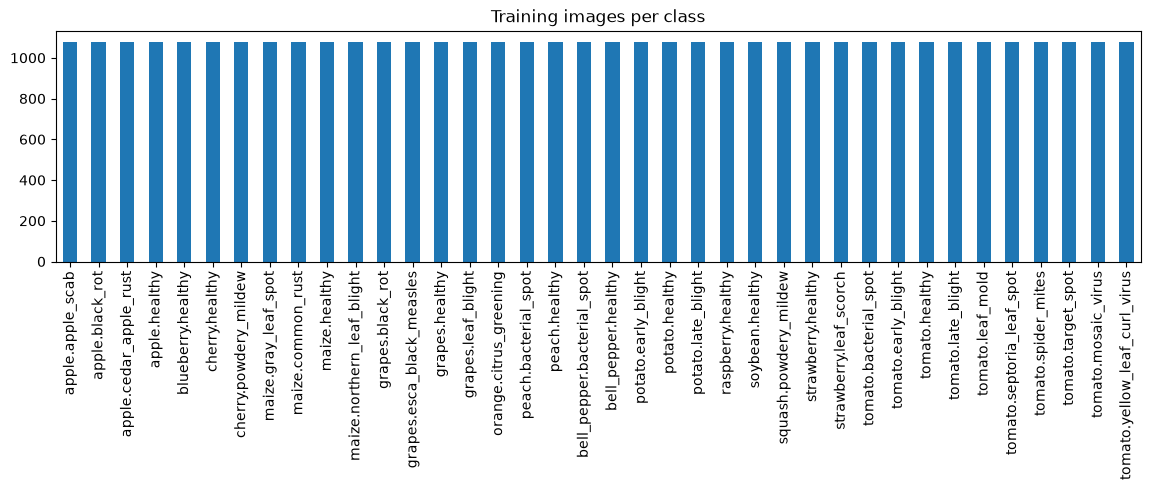

In [4]:
counts = pd.Series([label for _, label in train_samples]).value_counts()
counts.plot.bar(figsize=(14, 3), title="Training images per class");

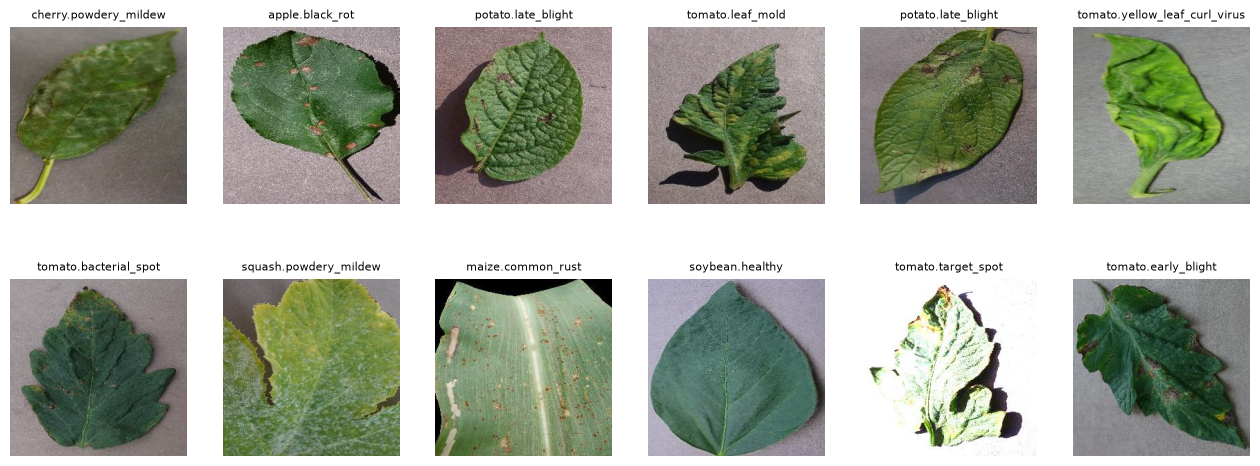

In [5]:
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, (path, label) in zip(axes.flat, pd.Series(train_samples).sample(12, random_state=1)):
    ax.imshow(Image.open(path)); ax.set_title(label, fontsize=8); ax.axis("off")

## Train
Stage 1 trains only the new classifier head; stage 2 fine-tunes the whole network at a lower learning rate. Early stopping keeps the best validation epoch.

In [6]:
config = vision.TrainConfig(
    architecture="mobilenet_v3_large",   # or "efficientnet_b0"
    image_size=224 if ON_GPU else 192,    # 192 px is ~35% cheaper on CPU; leaf lesions stay visible
    batch_size=64 if ON_GPU else 32,
    head_epochs=2 if ON_GPU else 1,
    finetune_epochs=8 if ON_GPU else 4,
    patience=2,
    num_workers=4,                        # set 0 if the DataLoader hangs on Windows
)
trained = vision.train(train_samples, valid_samples, config)

Training mobilenet_v3_large on cpu — 41040 train / 4560 valid images, 38 classes


[head] epoch 1/1  train 1.196/0.862  valid 0.974/0.934  (486s)


[finetune] epoch 1/4  train 0.838/0.975  valid 0.762/0.989  (2155s)


[finetune] epoch 2/4  train 0.751/0.992  valid 0.717/0.996  (914s)


[finetune] epoch 3/4  train 0.723/0.995  valid 0.700/0.998  (967s)


[finetune] epoch 4/4  train 0.709/0.997  valid 0.693/0.998  (1322s)


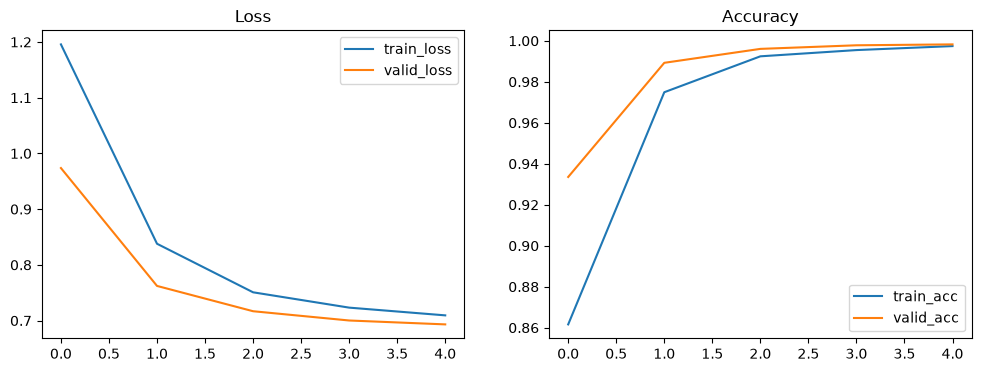

In [7]:
history = pd.DataFrame(trained.history)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
history[["train_loss", "valid_loss"]].plot(ax=a, title="Loss"); history[["train_acc", "valid_acc"]].plot(ax=b, title="Accuracy");

## Evaluate on the untouched test set
`min_confidence` is calibrated here: below it, accepted predictions would be less than 97 % accurate, so the app asks the farmer for a clearer photo instead of guessing.

In [8]:
metrics = vision.evaluate(trained, test_samples)
pd.Series({k: v for k, v in metrics.items() if k != "class_counts_test"})

test_accuracy                     0.9979
test_macro_f1                     0.9978
test_top3_accuracy                0.9999
min_confidence                    0.3000
coverage_at_min_confidence        0.9999
accuracy_at_min_confidence        0.9980
test_images                   17572.0000
dtype: float64

In [9]:
from sklearn.metrics import classification_report

probabilities, targets = vision.predict_probabilities(trained.model, test_samples, trained.labels, config.image_size)
print(classification_report(targets, probabilities.argmax(1), target_names=trained.labels, digits=3))

                               precision    recall  f1-score   support

             apple.apple_scab      1.000     1.000     1.000       504
              apple.black_rot      1.000     1.000     1.000       497
       apple.cedar_apple_rust      1.000     1.000     1.000       440
                apple.healthy      1.000     1.000     1.000       502
   bell_pepper.bacterial_spot      0.998     1.000     0.999       478
          bell_pepper.healthy      0.998     0.998     0.998       497
            blueberry.healthy      0.998     1.000     0.999       454
               cherry.healthy      1.000     0.998     0.999       456
        cherry.powdery_mildew      1.000     1.000     1.000       421
             grapes.black_rot      1.000     0.998     0.999       472
    grapes.esca_black_measles      0.998     1.000     0.999       480
               grapes.healthy      1.000     1.000     1.000       423
           grapes.leaf_blight      1.000     1.000     1.000       430
     

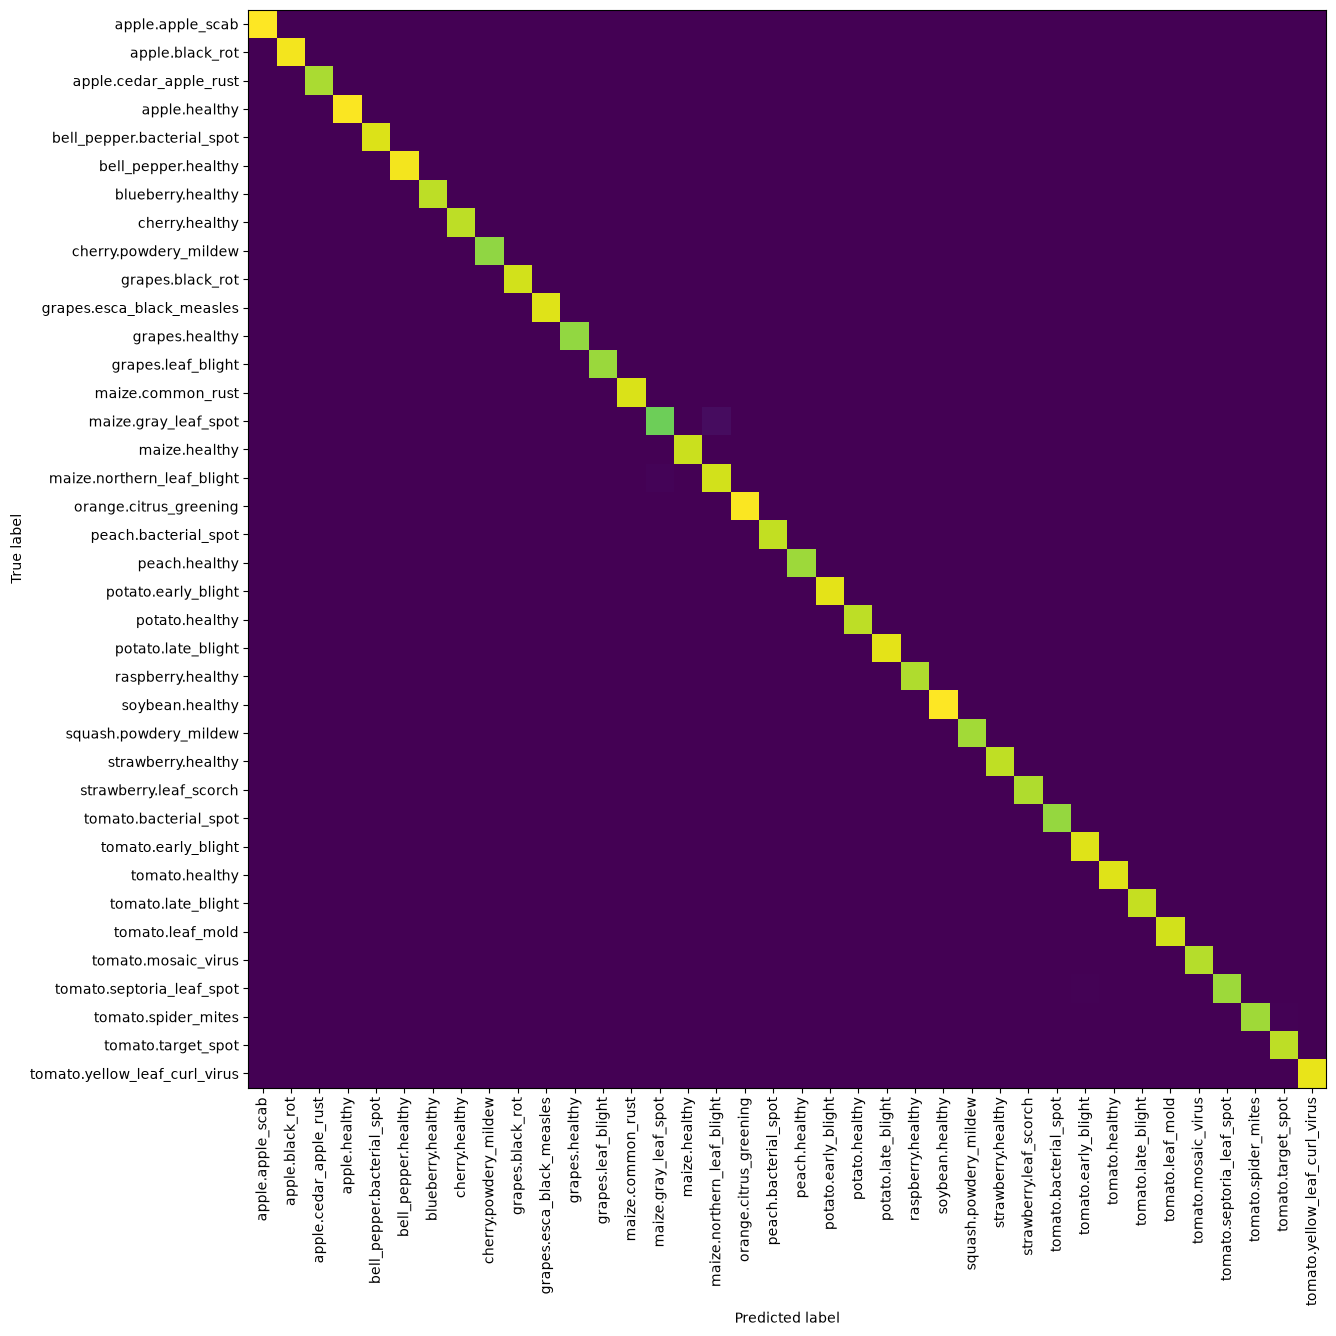

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(targets, probabilities.argmax(1), display_labels=trained.labels,
                                        xticks_rotation=90, ax=ax, colorbar=False, include_values=False)

## Export to ONNX (+ INT8 if it keeps accuracy)
The export is checked numerically against PyTorch. INT8 is calibrated on validation images and served only if it loses ≤ 1 accuracy point.

In [11]:
directory = vision.export_onnx(trained, "disease", DATA, quantize_with=valid_samples)

[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNX matches PyTorch (max abs diff 3.23e-06)


Quantisation: {'fp32_accuracy': 1.0, 'int8_accuracy': 0.995, 'served': 'int8', 'fp32_mb': 17.3, 'int8_mb': 4.9}


Exported C:\AgriSmart\ml\artifacts\disease\disease_v1


## Put the model live

Versions are never overwritten — each export creates a new `…_vN` folder. To serve it:

* **Admin dashboard → Models →** *Register* and tick *Activate*, or
* from `backend/`: `python -m app.cli register-model disease <version> --activate`

Rolling back is the same command with the previous version (`activate-model`). Every API
instance picks up the change within a minute — no restart.


**Before production:** have an agronomist review every entry in the knowledge base and mark it verified in *Admin → Diseases*. Until then the app adds a caution to every answer.